DEA

In [1]:
import pandas as pd
import pulp
import matplotlib.pyplot as plt

In [2]:
# Load CSV file
file_path = r'C:\Users\levyg\OneDrive\Desktop\Engenharia\Mestrado\Mestrado\Tópicos especiais em sistemas de apoio à decisão\DEA\Desenvolvimento DEA AHP\ARTIGO DEA GAUSSIANO CORREÇÃO PEARSON\base dados restaurantes.csv'
df = pd.read_csv(file_path, sep=';')

In [3]:
# Group by 'Estabelecimento' and sum the values
df_grouped = df.groupby('Estabelecimento').agg({
    'Qtd': 'sum',
    'Custo total': 'sum',
    'Lucro Bruto': 'sum'
}).reset_index()

df_grouped

,Estabelecimento,Qtd,Custo total,Lucro Bruto
0,RESTAURANT A,233655,1673115.11,3241039.50
1,RESTAURANT B,165480,1112546.22,1538799.72
2,RESTAURANT C,137177,953469.73,1564098.94
3,RESTAURANT D,111187,918028.02,1239982.62


In [4]:
# Define DMUs, inputs, and outputs
DMUs = df_grouped['Estabelecimento'].tolist()
inputs = df_grouped[['Qtd', 'Custo total']].values
outputs = df_grouped[['Lucro Bruto']].values


CRS

In [5]:
# Function to perform DEA CRS
def dea_crs(inputs, outputs, DMUs):
    num_dmus = len(DMUs)
    num_inputs = inputs.shape[1]
    num_outputs = outputs.shape[1]
    
    results = []
    
    for dmu in range(num_dmus):
        # Create the problem
        prob = pulp.LpProblem(f"DEA_CRS_DMU_{DMUs[dmu]}", pulp.LpMaximize)
        
        # Define decision variables (weights for inputs and outputs)
        u = pulp.LpVariable.dicts("u", range(num_outputs), lowBound=0)
        v = pulp.LpVariable.dicts("v", range(num_inputs), lowBound=0)
        
        # Objective function: maximize the efficiency of the DMU
        prob += pulp.lpSum([u[j] * outputs[dmu][j] for j in range(num_outputs)])
        
        # Constraints: efficiency of all DMUs should be <= 1
        for i in range(num_dmus):
            prob += pulp.lpSum([u[j] * outputs[i][j] for j in range(num_outputs)]) - \
                    pulp.lpSum([v[k] * inputs[i][k] for k in range(num_inputs)]) <= 0
        
        # Normalization constraint: sum of input weights = 1
        prob += pulp.lpSum([v[k] * inputs[dmu][k] for k in range(num_inputs)]) == 1
        
        # Solve the problem
        prob.solve()
        
        # Extract results
        efficiency = pulp.value(prob.objective)
        u_values = [pulp.value(u[j]) for j in range(num_outputs)]
        v_values = [pulp.value(v[k]) for k in range(num_inputs)]
        
        # Calculate weighted inputs and outputs
        weighted_inputs = sum([v_values[k] * inputs[dmu][k] for k in range(num_inputs)])
        weighted_outputs = sum([u_values[j] * outputs[dmu][j] for j in range(num_outputs)])
        
        results.append({
            'DMU': DMUs[dmu],
            'Qtd': inputs[dmu][0],
            'Custo total': inputs[dmu][1],
            'Lucro Bruto': outputs[dmu][0],
            'weight_Qtd': v_values[0],
            'weight_Custo_total': v_values[1],
            'weight_Lucro_Bruto': u_values[0],
            'inputs_weighted': weighted_inputs,
            'outputs_weighted': weighted_outputs,
            'efficiency': efficiency
        })
    
    # Convert results to DataFrame
    df_crs = pd.DataFrame(results)
    
    # Add ranking column (1 = most efficient, higher numbers = less efficient)
    df_crs['Ranking'] = df_crs['efficiency'].rank(ascending=False, method='min').astype(int)
    
    # Sort by ranking (most efficient to least efficient)
    df_crs = df_crs.sort_values(by='Ranking').reset_index(drop=True)
    
    return df_crs

# Run DEA CRS
df_crs = dea_crs(inputs, outputs, DMUs)

# Save results to CSV
df_crs.to_csv('dea_crs_results.csv', index=False)

print("DEA CRS Results with Ranking:")
df_crs

C:\Users\levyg\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pulp\pulp.py:1298: UserWarning: Spaces are not permitted in the name. Converted to '_'
  warnings.warn("Spaces are not permitted in the name. Converted to '_'")


DEA CRS Results with Ranking:


,DMU,Qtd,Custo total,Lucro Bruto,weight_Qtd,weight_Custo_total,weight_Lucro_Bruto,inputs_weighted,outputs_weighted,efficiency,Ranking
0,RESTAURANT A,233655.0,1673115.11,3241039.50,0.000000,5.976875e-07,3.085430e-07,1.0,1.000000,1.000000,1
1,RESTAURANT C,137177.0,953469.73,1564098.94,0.000000,1.048801e-06,5.414204e-07,1.0,0.846835,0.846835,2
2,RESTAURANT B,165480.0,1112546.22,1538799.72,0.000000,8.988391e-07,5.479294e-07,1.0,0.843154,0.843154,3
3,RESTAURANT D,111187.0,918028.02,1239982.62,0.000009,0.000000e+00,6.483906e-07,1.0,0.803993,0.803993,4


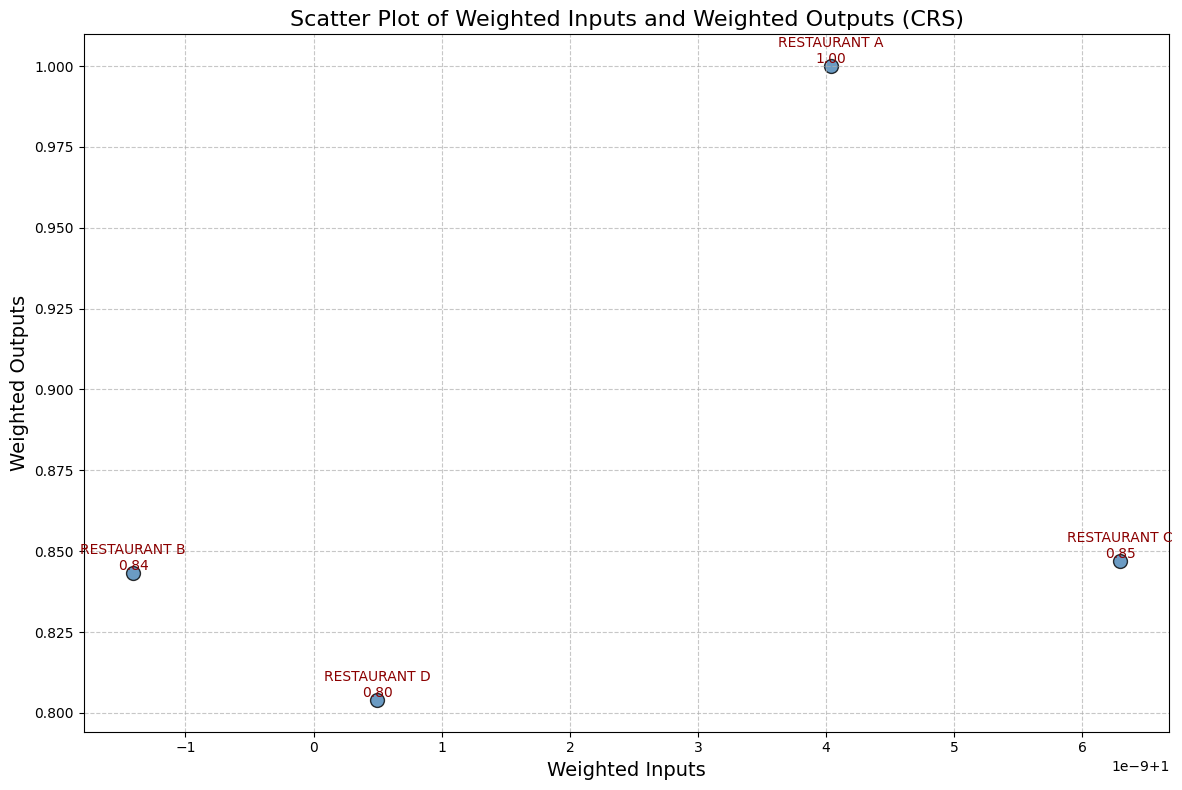

In [6]:
# Plot the scatter plot
plt.figure(figsize=(12, 8))

# Create the scatter plot
plt.scatter(
    df_crs['inputs_weighted'],  # Weighted Inputs on the X-axis
    df_crs['outputs_weighted'],  # Weighted Outputs on the Y-axis
    s=100,  # Size of the points
    alpha=0.8,  # Transparency of the points
    color='steelblue',  # Color of the points
    edgecolors='k'  # Outline of the points
)

# Add data labels (DMU and Efficiency)
for i in range(len(df_crs)):
    dmu = df_crs['DMU'].iloc[i]
    eficiencia = df_crs['efficiency'].iloc[i]
    x = df_crs['inputs_weighted'].iloc[i]
    y = df_crs['outputs_weighted'].iloc[i]
    plt.text(
        x, y, 
        f'{dmu}\n{eficiencia:.2f}', 
        fontsize=10, ha='center', va='bottom', color='darkred'
    )

# Add labels and title
plt.title('Scatter Plot of Weighted Inputs and Weighted Outputs (CRS)', fontsize=16)
plt.xlabel('Weighted Inputs', fontsize=14)
plt.ylabel('Weighted Outputs', fontsize=14)

# Adjust grid for better visualization
plt.grid(True, linestyle='--', alpha=0.7)

# Display the plot
plt.tight_layout()
plt.show()

VRS

In [7]:
# Function to perform DEA VRS
def dea_vrs(inputs, outputs, DMUs):
    num_dmus = len(DMUs)
    num_inputs = inputs.shape[1]
    num_outputs = outputs.shape[1]
    
    results = []
    
    for dmu in range(num_dmus):
        # Create the problem
        prob = pulp.LpProblem(f"DEA_VRS_DMU_{DMUs[dmu]}", pulp.LpMaximize)
        
        # Define decision variables (weights for inputs and outputs)
        u = pulp.LpVariable.dicts("u", range(num_outputs), lowBound=0)
        v = pulp.LpVariable.dicts("v", range(num_inputs), lowBound=0)
        u0 = pulp.LpVariable("u0", cat='Continuous')  # Free variable for VRS
        
        # Objective function: maximize the efficiency of the DMU
        prob += pulp.lpSum([u[j] * outputs[dmu][j] for j in range(num_outputs)]) + u0
        
        # Constraints: efficiency of all DMUs should be <= 1
        for i in range(num_dmus):
            prob += pulp.lpSum([u[j] * outputs[i][j] for j in range(num_outputs)]) - \
                    pulp.lpSum([v[k] * inputs[i][k] for k in range(num_inputs)]) + u0 <= 0
        
        # Normalization constraint: sum of input weights = 1
        prob += pulp.lpSum([v[k] * inputs[dmu][k] for k in range(num_inputs)]) == 1
        
        # Solve the problem
        prob.solve()
        
        # Extract results
        efficiency = pulp.value(prob.objective)
        u_values = [pulp.value(u[j]) for j in range(num_outputs)]
        v_values = [pulp.value(v[k]) for k in range(num_inputs)]
        u0_value = pulp.value(u0)
        
        # Calculate weighted inputs and outputs
        weighted_inputs = sum([v_values[k] * inputs[dmu][k] for k in range(num_inputs)])
        weighted_outputs = sum([u_values[j] * outputs[dmu][j] for j in range(num_outputs)]) + u0_value
        
        results.append({
            'DMU': DMUs[dmu],
            'Qtd': inputs[dmu][0],
            'Custo total': inputs[dmu][1],
            'Lucro Bruto': outputs[dmu][0],
            'weight_Qtd': v_values[0],
            'weight_Custo_total': v_values[1],
            'weight_Lucro_Bruto': u_values[0],
            'inputs_weighted': weighted_inputs,
            'outputs_weighted': weighted_outputs,
            'efficiency': efficiency
        })
    
    # Convert results to DataFrame
    df_vrs = pd.DataFrame(results)
    
    # Add ranking column (1 = most efficient, higher numbers = less efficient)
    df_vrs['Ranking'] = df_vrs['efficiency'].rank(ascending=False, method='min').astype(int)
    
    # Sort by ranking (most efficient to least efficient)
    df_vrs = df_vrs.sort_values(by='Ranking').reset_index(drop=True)
    
    return df_vrs

# Run DEA VRS
df_vrs = dea_vrs(inputs, outputs, DMUs)

# Save results to CSV
df_vrs.to_csv('dea_vrs_results.csv', index=False)

print("DEA VRS Results with Ranking:")
df_vrs

C:\Users\levyg\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pulp\pulp.py:1298: UserWarning: Spaces are not permitted in the name. Converted to '_'
  warnings.warn("Spaces are not permitted in the name. Converted to '_'")


DEA VRS Results with Ranking:


,DMU,Qtd,Custo total,Lucro Bruto,weight_Qtd,weight_Custo_total,weight_Lucro_Bruto,inputs_weighted,outputs_weighted,efficiency,Ranking
0,RESTAURANT D,111187.0,918028.02,1239982.62,0.000009,0.000000e+00,5.504390e-07,1.0,1.00000,1.00000,1
1,RESTAURANT C,137177.0,953469.73,1564098.94,0.000000,1.048801e-06,1.146851e-07,1.0,1.00000,1.00000,2
2,RESTAURANT A,233655.0,1673115.11,3241039.50,0.000003,2.011537e-07,2.496819e-07,1.0,1.00000,1.00000,3
3,RESTAURANT B,165480.0,1112546.22,1538799.72,0.000000,8.988391e-07,3.391716e-07,1.0,0.92651,0.92651,4


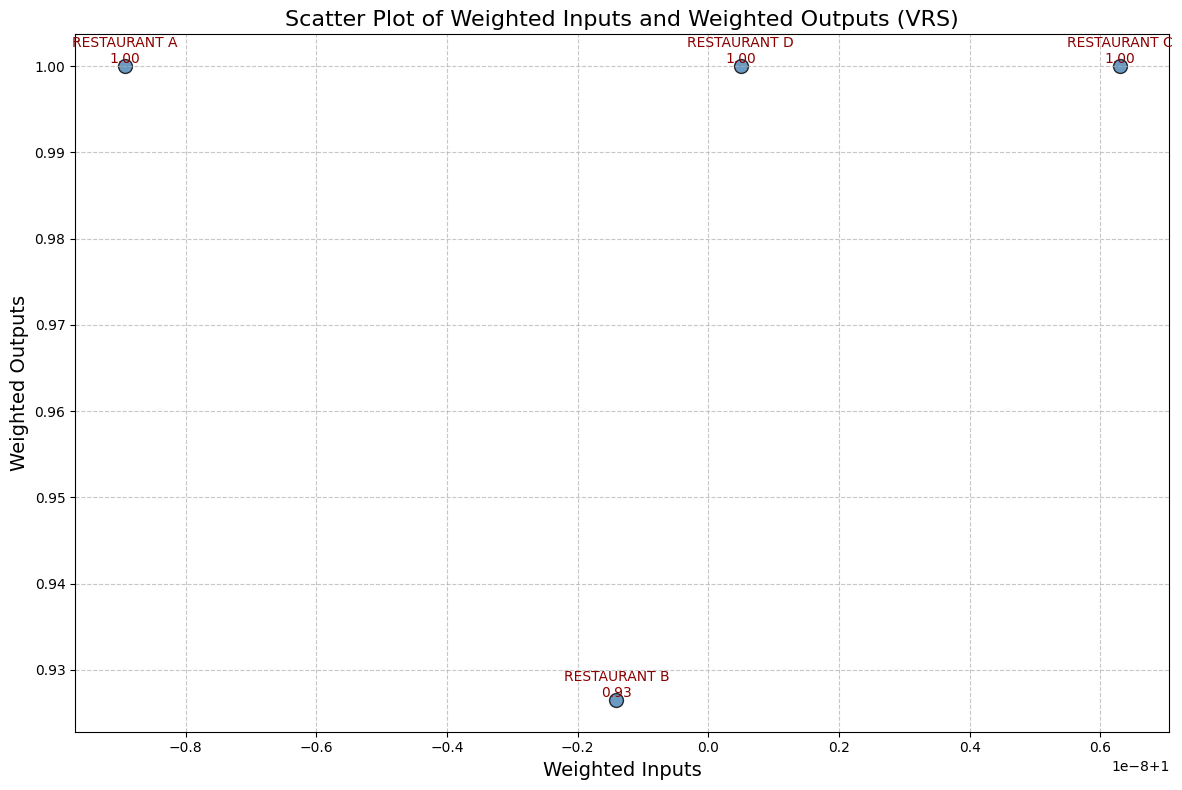

In [8]:
# Plot the scatter plot
plt.figure(figsize=(12, 8))

# Create the scatter plot
plt.scatter(
    df_vrs['inputs_weighted'],  # Weighted Inputs on the X-axis
    df_vrs['outputs_weighted'],  # Weighted Outputs on the Y-axis
    s=100,  # Size of the points
    alpha=0.8,  # Transparency of the points
    color='steelblue',  # Color of the points
    edgecolors='k'  # Outline of the points
)

# Add data labels (DMU and Efficiency)
for i in range(len(df_vrs)):
    dmu = df_vrs['DMU'].iloc[i]
    eficiencia = df_vrs['efficiency'].iloc[i]
    x = df_vrs['inputs_weighted'].iloc[i]
    y = df_vrs['outputs_weighted'].iloc[i]
    plt.text(
        x, y, 
        f'{dmu}\n{eficiencia:.2f}', 
        fontsize=10, ha='center', va='bottom', color='darkred'
    )

# Add labels and title
plt.title('Scatter Plot of Weighted Inputs and Weighted Outputs (VRS)', fontsize=16)
plt.xlabel('Weighted Inputs', fontsize=14)
plt.ylabel('Weighted Outputs', fontsize=14)

# Adjust grid for better visualization
plt.grid(True, linestyle='--', alpha=0.7)

# Display the plot
plt.tight_layout()
plt.show()